# Taller Forecasting


## 1.1 Introduccion al analisis de ST
En este trabajo se utilizará la base de datos `Time Series Forecasting with Yahoo Stock Price`, disponible en [Kaggle](https://www.kaggle.com/datasets/arashnic/time-series-forecasting-with-yahoo-stock-price?select=yahoo_stock.csv),  contiene información histórica sobre el precio de las acciones del `S&P500`.

Su análisis busca comprender las fluctuaciones del mercado bursátil y evaluar cómo los datos históricos pueden contribuir a construir modelos de pronóstico que apoyen la toma de decisiones financieras.

In [68]:
#pip install pmdarima

## Importamos dependencias

In [84]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import warnings

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error

import pmdarima as pm

## Cargamos los datos

In [70]:
# Download latest version
path = kagglehub.dataset_download("arashnic/time-series-forecasting-with-yahoo-stock-price")

print("Path to dataset files:", path)
# 3. Ver la lista de archivos CSV que contiene la carpeta
archivos = os.listdir(path)
print(archivos)

Using Colab cache for faster access to the 'time-series-forecasting-with-yahoo-stock-price' dataset.
Path to dataset files: /kaggle/input/time-series-forecasting-with-yahoo-stock-price
['yahoo_stock.csv']


In [71]:
ruta_application_train = os.path.join(path, 'yahoo_stock.csv')

df = pd.read_csv(ruta_application_train, sep=',')
df.head()

,Date,High,Low,Open,Close,Volume,Adj Close
0,2015-11-23,2095.610107,2081.389893,2089.409912,2086.590088,3.587980e+09,2086.590088
1,2015-11-24,2094.120117,2070.290039,2084.419922,2089.139893,3.884930e+09,2089.139893
2,2015-11-25,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
3,2015-11-26,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
4,2015-11-27,2093.290039,2084.129883,2088.820068,2090.110107,1.466840e+09,2090.110107


In [72]:
print(f'Rango de fechas: {df['Date'].min()} - {df['Date'].max()}')

Rango de fechas: 2015-11-23 - 2020-11-20


Se seleccionan las columnas de Date y Open, por lo que lo que se va a predecir es el valor de apertura de las acciones de `S&P500` basandose en datos disponibles entre el 2015-11-23 y 2020-11-20.

## Valores nulos

In [73]:
df = df.iloc[:,[0,3]]
print(df.shape)
df.info()

(1825, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1825 non-null   object 
 1   Open    1825 non-null   float64
dtypes: float64(1), object(1)
memory usage: 28.6+ KB


## Ajustando el formato de la fecha y convirtiendola en indice

In [90]:
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Open'] = df['Open'].round(2)
df_idx = df.set_index('Date')
df_idx.head()

,Open,Year,Month
Date,,,
2015-11-23,2089.41,2015,11
2015-11-24,2084.42,2015,11
2015-11-25,2089.30,2015,11
2015-11-26,2089.30,2015,11
2015-11-27,2088.82,2015,11


## 2. Exploración de la Base de Datos

2.1 ¿Qué tipo de información se puede obtener al visualizar una serie de tiempo? Menciona al menos tres aspectos que se pueden identificar mediante la visualización.

A. Tendencia (Trend): Indica la dirección general a largo plazo en la que se mueven los datos (por ejemplo, si los precios de las acciones muestran un crecimiento sostenido, un decrecimiento o si se mantienen estables).

B. Estacionalidad (Seasonality): Revela patrones o fluctuaciones repetitivas que ocurren a intervalos de tiempo regulares y predecibles (como el aumento de ventas de ciertos productos en navidad o variaciones climáticas por estaciones).

C. Volatilidad y Ruido (Variabilidad/Outliers): Permite observar qué tan dispersos o variables son los datos en períodos cortos (volatilidad) y detectar comportamientos inusuales, valores atípicos (outliers) o rupturas estructurales debidas a eventos imprevistos.

 2.2 Identifica las variables disponibles y la naturaleza de los datos de series de tiempo.

|Variable|Descripcion|Naturaleza|
|---|---|---|
|Date|Representa la fecha en la que se registra el precio de la acción|Temporal|
|Open|Corresponde al precio de apertura de la acción en la fecha registrada|Cuantitativa continua|

### Graficando la serie

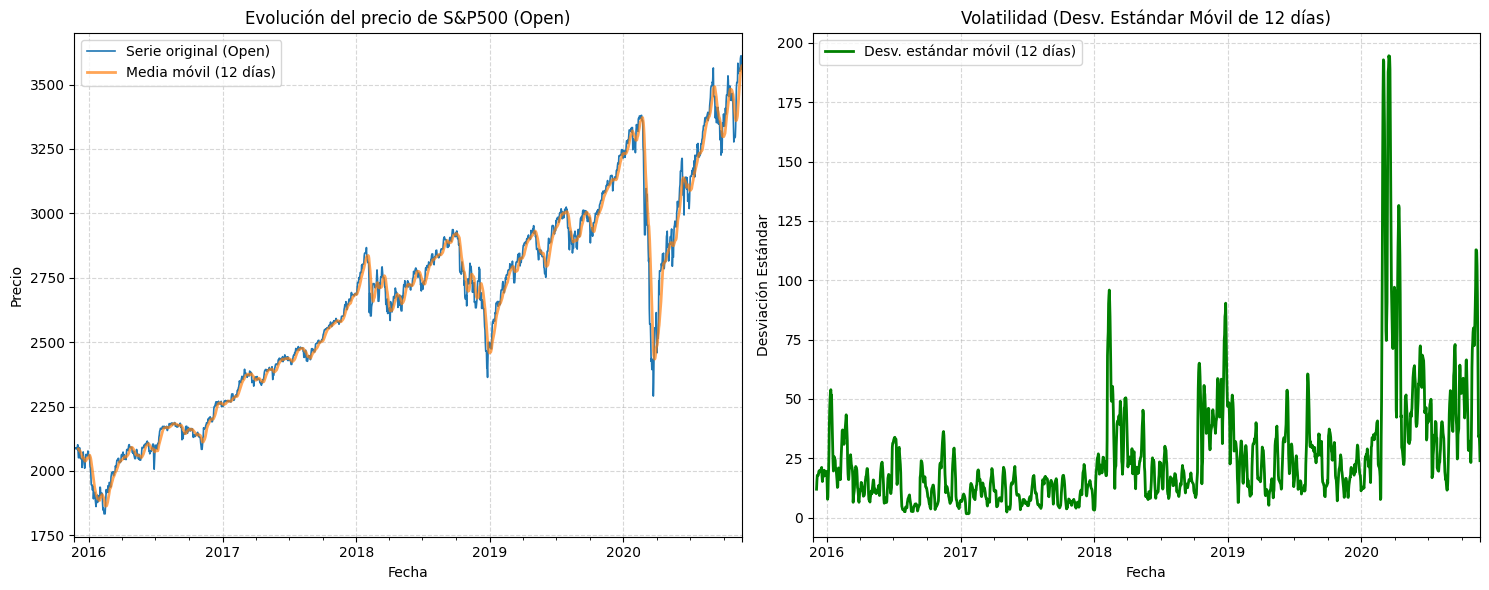

In [82]:
serie = df_idx['Open']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Primer gráfico: Serie original y Media Móvil
serie.plot(ax=ax1, label="Serie original (Open)", linewidth=1.2)
serie.rolling(12).mean().plot(ax=ax1, label="Media móvil (12 días)", linewidth=2, alpha=0.7)
ax1.set_title("Evolución del precio de S&P500 (Open)")
ax1.set_ylabel("Precio")
ax1.set_xlabel("Fecha")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Segundo gráfico: Desviación Estándar Móvil
serie.rolling(12).std().plot(ax=ax2, label="Desv. estándar móvil (12 días)", linewidth=2, color='green')
ax2.set_title("Volatilidad (Desv. Estándar Móvil de 12 días)")
ax2.set_ylabel("Desviación Estándar")
ax2.set_xlabel("Fecha")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

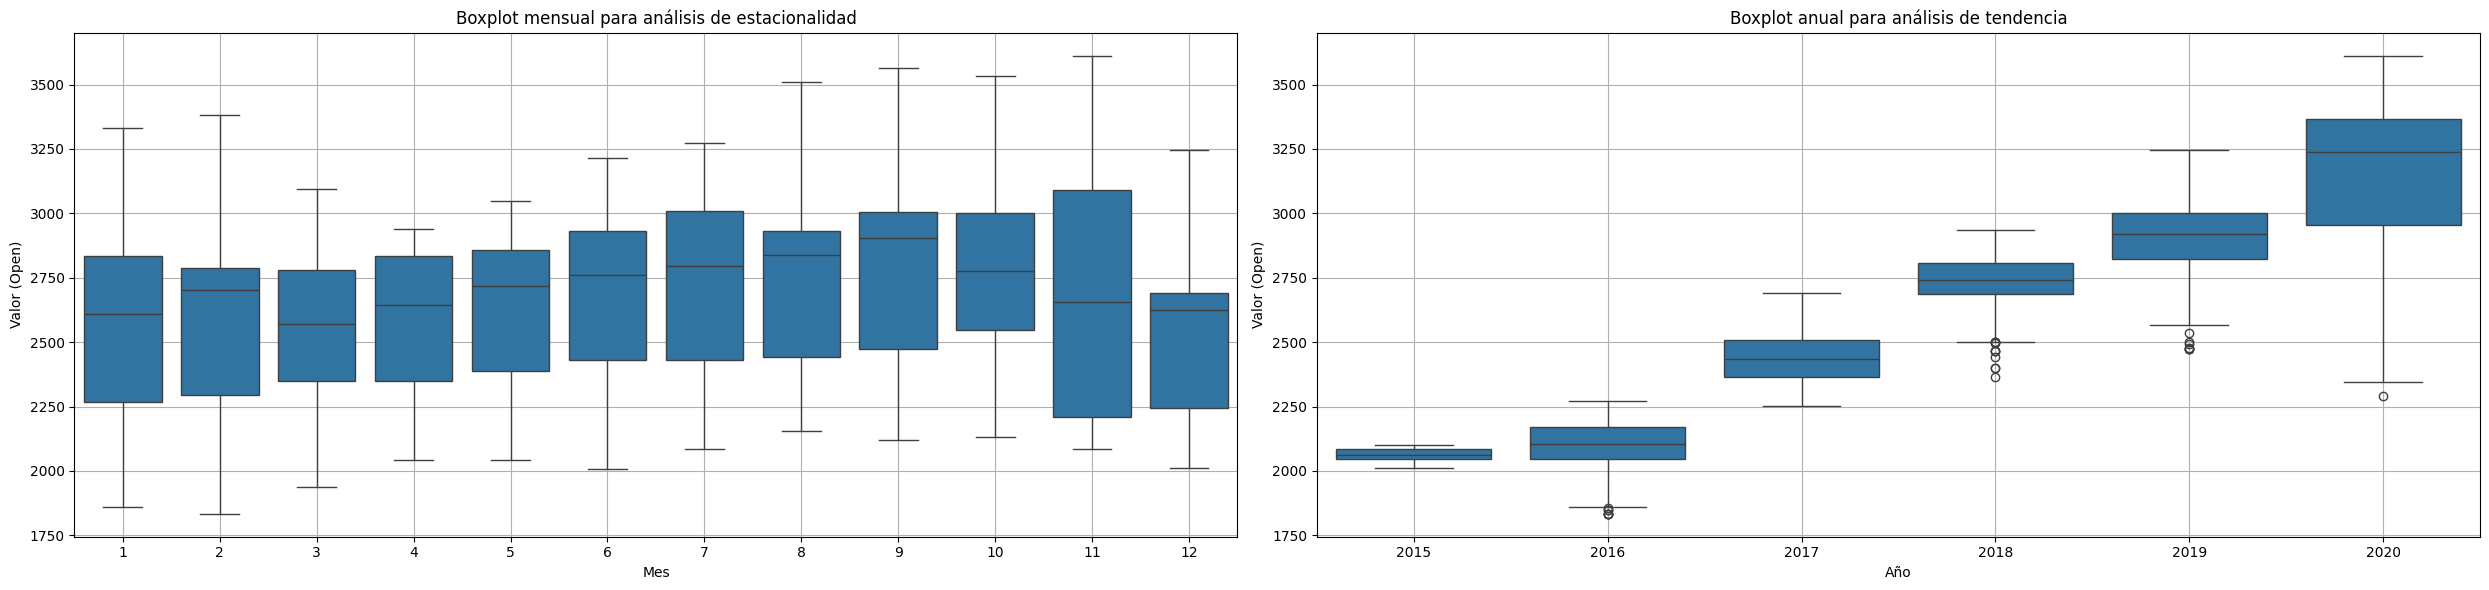

In [93]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(25, 6))

# Subplot 1: Distribución mensual (Estacionalidad)
sns.boxplot(x='Month', y='Open', data=df_idx, ax=ax1)
ax1.set_title('Boxplot mensual para análisis de estacionalidad')
ax1.set_xlabel('Mes')
ax1.set_ylabel('Valor (Open)')
ax1.grid(True)

# Subplot 2: Distribución anual (Tendencia/Crecimiento)
sns.boxplot(x='Year', y='Open', data=df_idx, ax=ax2)
ax2.set_title('Boxplot anual para análisis de tendencia')
ax2.set_xlabel('Año')
ax2.set_ylabel('Valor (Open)')
ax2.grid(True)

plt.tight_layout()
plt.show()

### Prueba de estacionariedad: ADF

Un modelo ARIMA necesita una serie **estacionaria** (media y varianza constantes en el tiempo) en la parte no estacional. Usamos la prueba **ADF (Augmented Dickey-Fuller)**, vista en clase:

- H0: la serie **tiene raíz unitaria** (no es estacionaria).
- H1: la serie **no tiene raíz unitaria** (es estacionaria).

Si el p-valor es menor que el nivel de significancia (0.05), rechazamos H0 y concluimos que la serie es estacionaria.

In [102]:
def prueba_adf(serie, nombre=""):
    resultado = adfuller(serie.dropna(), autolag="AIC")
    print(f"--- ADF: {nombre} ---")
    print(f"Estadístico: {resultado[0]:.4f} | p-valor: {resultado[1]:.4f}")
    for clave, valor in resultado[4].items():
        print(f"  Valor crítico {clave}: {valor:.4f}")
    es_estacionaria = resultado[1] < 0.05
    print(f"Conclusión (alfa=0.05): {'Estacionaria' if es_estacionaria else 'No estacionaria'}\n")
    return es_estacionaria

_ = prueba_adf(df_idx['Open'], "serie original")

--- ADF: serie original ---
Estadístico: -0.8539 | p-valor: 0.8028
  Valor crítico 1%: -3.4340
  Valor crítico 5%: -2.8631
  Valor crítico 10%: -2.5676
Conclusión (alfa=0.05): No estacionaria



/tmp/ipykernel_1655/664524098.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(serie.dropna(), autolag="AIC")


La prueba ADF indica que la serie **no es estacionaria**

2.3 Realiza un análisis exploratorio de los datos consignados en esta base de datos. ¿Qué tipo de análisis estadístico se puede realizar en una serie de tiempo para comprender mejor suscaracterísticas? Utiliza una librería Python para trazar la serie de tiempo de la variable seleccionada, identificando tendencias, estacionalidad y otros patrones visuales.

  a. Tendencia (Trend): La serie de tiempo presenta un tendencia incremental, con una caida cerca del 2020 (COVID-19)

  b. Estacionalidad (Seasonality): Se presenta una aparente estacionalidad

  c. Volatilidad y Ruido (Variabilidad/Outliers): De la grafica de desviacion se puede evidenciar volatilidad en la serie de tiempo.


2.4 Calcula estadísticas descriptivas básicas de la serie de tiempo, como la media, la mediana, la desviación estándar, etc ¿Qué puedes concluir acerca de estos resultados?


In [83]:
df_idx.describe()

,Open
count,1825.000000
mean,2647.704751
std,407.169995
min,1833.400000
25%,2341.980000
50%,2685.490000
75%,2913.860000
max,3612.090000


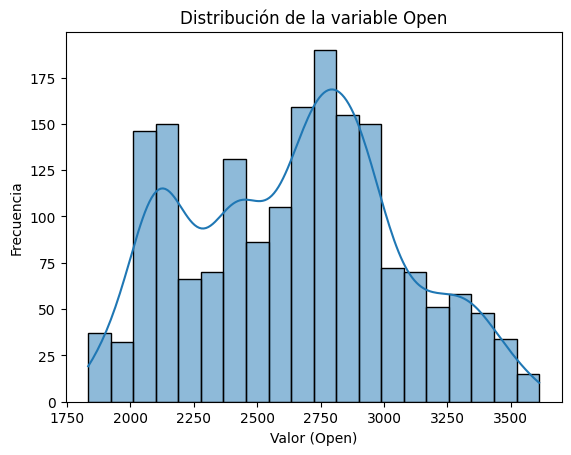

In [99]:
sns.histplot(df_idx['Open'], kde=True)
plt.title('Distribución de la variable Open')
plt.xlabel('Valor (Open)')
plt.ylabel('Frecuencia')
plt.show()

* La media (2647.70) y la mediana (2685.98) tienen valores cercanos, lo que indicaría una baja presencia de atipicos

* No se presentan sesgos pronunciados

* Existe una tendencia alcista.



## 3. Preparación de los datos
Realiza el preprocesamiento necesario en la base de datos, como la limpieza de datos faltantes, la conversión de tipos de datos y la selección de la variable de interés.

Estos pasos ya se realizaron

## 4. Modelado y predicción
Utiliza statsmodels u otra biblioteca para ajustar un modelo de series de tiempo apropiado a los
datos y realizar predicciones futuras. Pueden seleccionar una ventana temporal para la predicción,
sustentando adecuadamente por qué.